<a href="https://colab.research.google.com/github/pushkar-git438/statistical-foundation-of-data-science/blob/main/Practical4/practical4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Imported the libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as pyplot

# I loaded the Teaching Ratings dataset from a CSV file using Pandas. The head() function shows the first five rows of the dataset.

In [ ]:
ratings_url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ST0151EN-SkillsNetwork/labs/teachingratings.csv"

ratings_df = pd.read_csv(ratings_url)

ratings_df.head()

,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof,PrimaryLast,vismin,female,single_credit,upper_division,English_speaker,tenured_prof
0,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1,0,1,1,0,1,1,1
1,yes,36,female,more,0.289916,3.7,upper,yes,yes,86,125,1,0,1,1,0,1,1,1
2,yes,36,female,more,0.289916,3.6,upper,yes,yes,76,125,1,0,1,1,0,1,1,1
3,yes,36,female,more,0.289916,4.4,upper,yes,yes,77,123,1,1,1,1,0,1,1,1
4,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2,0,0,0,0,1,1,1


# The prof column identifies the professors. I used duplicated() to find professors who appear more than once. keep=False displays all observations belonging to duplicated professors.

In [ ]:
duplicates = ratings_df[ratings_df.duplicated("prof", keep=False)]

duplicates

,minority,age,gender,credits,beauty,eval,division,native,tenure,students,allstudents,prof,PrimaryLast,vismin,female,single_credit,upper_division,English_speaker,tenured_prof
0,yes,36,female,more,0.289916,4.3,upper,yes,yes,24,43,1,0,1,1,0,1,1,1
1,yes,36,female,more,0.289916,3.7,upper,yes,yes,86,125,1,0,1,1,0,1,1,1
2,yes,36,female,more,0.289916,3.6,upper,yes,yes,76,125,1,0,1,1,0,1,1,1
3,yes,36,female,more,0.289916,4.4,upper,yes,yes,77,123,1,1,1,1,0,1,1,1
4,no,59,male,more,-0.737732,4.5,upper,yes,yes,17,20,2,0,0,0,0,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
451,no,32,male,more,1.231394,4.3,upper,yes,yes,52,86,93,1,0,0,0,1,1,1
452,yes,42,female,more,0.420400,3.3,upper,no,yes,48,84,94,0,1,1,0,1,0,1
453,yes,42,female,more,0.420400,3.3,upper,no,yes,52,67,94,0,1,1,0,1,0,1
454,yes,42,female,more,0.420400,3.2,upper,no,yes,54,66,94,0,1,1,0,1,0,1


# Here I used all observations in the dataset. mean() calculates the average age and std() calculates the standard deviation.

In [ ]:
print("Average age:", ratings_df["age"].mean())
print("Standard deviation of age:", ratings_df["age"].std())

Average age: 48.365010799136066
Standard deviation of age: 9.802742037864821


# I removed repeated observations based on the prof column and kept only one observation for each professor. This gives one row per instructor.

In [ ]:
one_professor = ratings_df.drop_duplicates("prof")

print("Number of observations:", len(one_professor))

Number of observations: 94


# Now I calculated the average age and standard deviation again, but this time using only one observation for each professor.


In [ ]:
print("Average age:", one_professor["age"].mean())
print("Standard deviation of age:", one_professor["age"].std())

Average age: 47.5531914893617
Standard deviation of age: 10.25651329515495


#I checked the unique values in the division column to see how the courses are categorized, such as lower-division and upper-division courses.

In [ ]:
ratings_df["division"].unique()

array(['upper', 'lower'], dtype=object)

#I grouped the instructors according to course division and calculated the average teaching evaluation for each division.

In [ ]:
division_eval = ratings_df.groupby("division")["eval"].mean()

print(division_eval)

division
lower    4.087261
upper    3.952614
Name: eval, dtype: float64


# I created a bar chart to compare the average teaching evaluation between the different course divisions. The taller bar represents the division with the higher average evaluation.

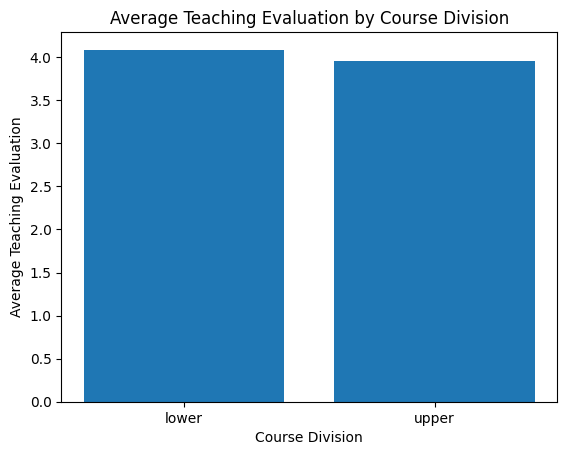

In [ ]:
pyplot.bar(division_eval.index, division_eval.values)

pyplot.xlabel("Course Division")
pyplot.ylabel("Average Teaching Evaluation")
pyplot.title("Average Teaching Evaluation by Course Division")

pyplot.show()